# Nhận dạng cảm xúc khuôn mặt (FER2013) → Emoji

**BTL cuối kỳ Trí tuệ nhân tạo – Chủ đề 3:** phân loại trạng thái cảm xúc khuôn mặt (đầu vào là ảnh, đầu ra là emoji).

Notebook được viết theo tài liệu *Tiêu chuẩn ảnh cho hệ thống nhận dạng cảm xúc khuôn mặt*, gồm 3 loại ảnh:

| Phần | Nội dung |
|---|---|
| 0 | Cài đặt, import, cấu hình |
| 1 | Ảnh **train** (FER2013: xám, 48x48, 1 kênh, 7 nhãn) |
| 2 | Xây dựng và huấn luyện mô hình (CNN hoặc MobileNetV2) |
| 3 | Đánh giá trên tập test của FER2013 |
| 4 | Ảnh **upload demo**: kiểm tra đầu vào, detect mặt, dự đoán ra emoji |
| 5 | Ảnh **test cho báo cáo** (10-15 ảnh gồm cả ảnh dễ và ảnh khó) |

**Lưu ý quan trọng:** tiền xử lý lúc demo phải **giống hệt** lúc train (chuyển xám → cắt mặt → resize 48x48 → chia 255). Vì vậy notebook dùng **một hàm duy nhất** `preprocess_gray_face()` cho cả train, đánh giá và demo.

## 0. Cài đặt, import và cấu hình

In [17]:
# Bỏ dấu # ở dòng dưới và chạy nếu chưa cài thư viện
# %pip install tensorflow opencv-python numpy pandas matplotlib scikit-learn ipywidgets pillow

In [18]:
import os
import random
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
    roc_auc_score,
)
from sklearn.preprocessing import LabelBinarizer
from sklearn.utils.class_weight import compute_class_weight
from IPython.display import clear_output
import warnings
warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print('TensorFlow', tf.__version__, '| OpenCV', cv2.__version__)

TensorFlow 2.22.0-rc1 | OpenCV 4.10.0


In [19]:
# ================== CẤU HÌNH CHUNG ==================
IMG_SIZE = 48          # FER2013: ảnh xám 48x48, 1 kênh
NUM_CLASSES = 7

# Thứ tự nhãn của FER2013 (0..6), trùng thứ tự trong tài liệu
LABELS = ['Angry', 'Disgust', 'Fear', 'Happy', 'Sad', 'Surprise', 'Neutral']
LABELS_VI = ['Giận', 'Ghê tởm', 'Sợ', 'Vui', 'Buồn', 'Ngạc nhiên', 'Bình thường']
EMOJIS = ['😠', '🤢', '😨', '😄', '😢', '😮', '😐']

# ----- Ngưỡng kiểm tra ảnh upload (demo) -----
MIN_FACE_SIZE = 100
MAX_DETECT_SIDE = 1600  # resize only the detector input for large photos
MAX_FILE_MB = 20
DARK_THRESHOLD = 60
BRIGHT_THRESHOLD = 200
BLUR_THRESHOLD = 100
LOW_CONFIDENCE = 0.40  # below this, report an uncertain prediction
ALLOWED_EXT = ('.jpg', '.jpeg', '.png')

# ----- Mô hình, dữ liệu và chế độ khởi động -----
MODEL_TYPE = 'mobilenetv2'
CSV_PATH = 'fer2013.csv'
MODEL_PATH = 'emotion_model.keras'
EPOCHS = 40  # classifier training epochs with early stopping
BATCH_SIZE = 256  # cached feature vectors are small
FEATURE_BATCH_SIZE = 16  # keep MobileNetV2 inference memory low

# FALSE = khởi động/demo/load model có sẵn, không huấn luyện lại
# TRUE = retrain the final classifier; keep the feature extractor frozen
RETRAIN_MODEL = False
AUTO_LOAD_MODEL = True

# ----- Ảnh test cho báo cáo -----
TEST_DIR = 'test_images'
TEST_CSV = 'test_labels.csv'


### Hàm tiền xử lý dùng chung (train = demo)

Đầu vào là ảnh **xám** (đã cắt mặt), đầu ra là mảng `(48, 48, 1)` float32 trong khoảng [0, 1]. Nếu lệch một bước nào giữa train và demo thì kết quả sẽ sai mà không báo lỗi, nên mọi nơi đều phải gọi hàm này.

In [20]:
def preprocess_gray_face(gray_face):
    '''Ảnh xám bất kỳ kích thước -> (48, 48, 1) float32 trong [0, 1].'''
    face = cv2.resize(gray_face, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    face = face.astype('float32') / 255.0
    return face[..., np.newaxis]

## 1. Ảnh dùng để train (FER2013)

FER2013: ảnh xám, 1 kênh, 48x48 px, mặt đã căn giữa, khoảng 35 nghìn ảnh, 7 nhãn.

Tải file `fer2013.csv` (Kaggle) và đặt cạnh notebook, hoặc sửa `CSV_PATH` ở trên.

In [ ]:
# Read FER2013 in chunks to avoid keeping the large pixel-string CSV in memory.
parts = {
    'Training': ([], []),
    'PublicTest': ([], []),
    'PrivateTest': ([], []),
}
for chunk in pd.read_csv(CSV_PATH, usecols=['emotion', 'pixels', 'Usage'], chunksize=512):
    for usage in parts:
        subset = chunk[chunk['Usage'] == usage]
        if subset.empty:
            continue
        x_part = np.empty((len(subset), IMG_SIZE, IMG_SIZE, 1), dtype=np.uint8)
        for row_idx, pixel_string in enumerate(subset['pixels'].values):
            x_part[row_idx, :, :, 0] = np.fromstring(pixel_string, sep=' ', dtype=np.uint8).reshape(IMG_SIZE, IMG_SIZE)
        parts[usage][0].append(x_part)
        parts[usage][1].append(subset['emotion'].to_numpy(dtype=np.int64))

def combine_split(usage):
    x_parts, y_parts = parts[usage]
    X = np.concatenate(x_parts).astype(np.float32) / 255.0
    y = np.concatenate(y_parts)
    return X, y

X_train, y_train = combine_split('Training')
X_val, y_val = combine_split('PublicTest')
X_test, y_test = combine_split('PrivateTest')
print('Train:', X_train.shape, '| Val:', X_val.shape, '| Test:', X_test.shape)
print('Pixel range:', X_train.min(), X_train.max())
del parts


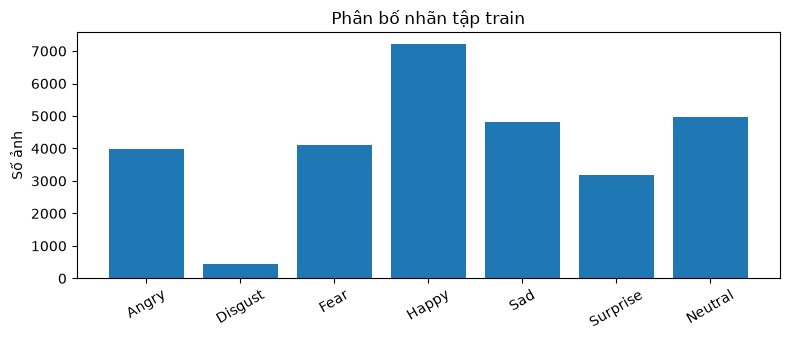

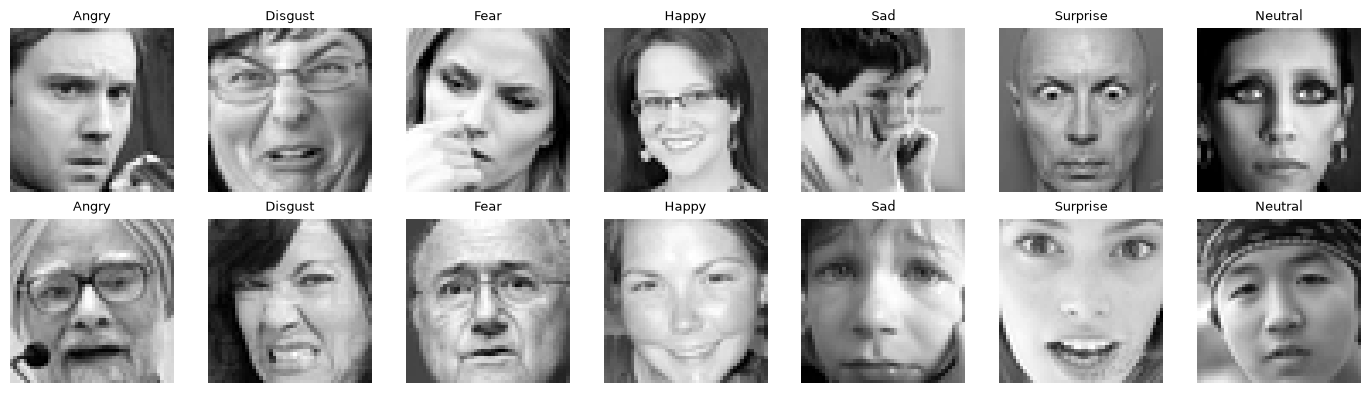

In [22]:
# Phân bố nhãn trong tập train (lớp Disgust rất ít ảnh nên sẽ dùng class weight)
counts = np.bincount(y_train, minlength=NUM_CLASSES)
plt.figure(figsize=(8, 3.5))
plt.bar(LABELS, counts)
plt.title('Phân bố nhãn tập train')
plt.ylabel('Số ảnh')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Xem thử vài ảnh mẫu
fig, axes = plt.subplots(2, 7, figsize=(14, 4))
for c in range(NUM_CLASSES):
    idx = np.where(y_train == c)[0][:2]
    for r, i in enumerate(idx):
        axes[r, c].imshow(X_train[i, :, :, 0], cmap='gray')
        axes[r, c].set_title(LABELS[c], fontsize=9)
        axes[r, c].axis('off')
plt.tight_layout()
plt.show()

## 2. Xây dựng và huấn luyện mô hình

Hai lựa chọn (đổi `MODEL_TYPE` ở phần cấu hình):

- **`cnn`**: CNN tự xây, nhận trực tiếp ảnh `48x48x1`.
- **`mobilenetv2`**: MobileNetV2 cần ảnh 3 kênh, kích thước từ 96x96 trở lên. Để tiền xử lý lúc demo vẫn giữ nguyên (xám, 48x48, chia 255), việc **resize lên 96x96 và nhân thành 3 kênh được đặt bên trong mô hình**.
With `RETRAIN_MODEL = True`, the notebook freezes the feature extractor, caches its features once, and trains the final classifier at a higher learning rate.

Set it back to `False` for normal demo use.

The saved classifier can also apply small class-bias offsets selected on PublicTest validation to improve macro-F1; PrivateTest is kept for final evaluation.



In [ ]:
def augmentation_block(x):
    # Data augmentation runs only during training; inference uses the original crop.
    x = layers.RandomFlip('horizontal', seed=SEED)(x)
    x = layers.RandomRotation(0.06, seed=SEED)(x)
    x = layers.RandomZoom(0.08, seed=SEED)(x)
    x = layers.RandomTranslation(0.05, 0.05, seed=SEED)(x)
    x = layers.RandomContrast(0.12, seed=SEED)(x)
    x = layers.RandomBrightness(0.10, seed=SEED)(x)
    x = layers.GaussianNoise(0.015, seed=SEED)(x)
    return x


def build_cnn():
    inp = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1))
    x = augmentation_block(inp)
    for filters in (32, 64, 128, 192):
        x = layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        x = layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Dropout(0.25)(x)
    x = layers.Flatten()(x)
    x = layers.Dense(256, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(0.55)(x)
    out = layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return models.Model(inp, out, name='emotion_cnn_augmented')


def build_mobilenetv2():
    inp = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1))
    x = augmentation_block(inp)
    x = layers.Resizing(96, 96)(x)
    x = layers.Concatenate()([x, x, x])
    x = layers.Rescaling(2.0, offset=-1.0)(x)
    base = tf.keras.applications.MobileNetV2(
        input_shape=(96, 96, 3), include_top=False, weights='imagenet')
    base.trainable = False
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.35)(x)
    out = layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return models.Model(inp, out, name='emotion_mobilenetv2')


original_classifier_weights = None
baseline_val_accuracy = None
if RETRAIN_MODEL and os.path.exists(MODEL_PATH):
    model = tf.keras.models.load_model(MODEL_PATH, compile=False)
    baseline_val_prob = model.predict(X_val, batch_size=FEATURE_BATCH_SIZE, verbose=0)
    baseline_val_accuracy = float(np.mean(np.argmax(baseline_val_prob, axis=1) == y_val))
    classifier = model.layers[-1]
    original_classifier_weights = classifier.get_weights()
    classifier.kernel.assign(tf.keras.initializers.GlorotUniform(seed=SEED)(classifier.kernel.shape))
    classifier.bias.assign(tf.zeros_like(classifier.bias))
    print('Loaded model and reset only its final classifier for retraining.')
elif AUTO_LOAD_MODEL and os.path.exists(MODEL_PATH) and not RETRAIN_MODEL:
    model = tf.keras.models.load_model(MODEL_PATH, compile=False)
    history = None
    print('Loaded saved model:', MODEL_PATH)
else:
    model = build_cnn() if MODEL_TYPE == 'cnn' else build_mobilenetv2()
    print('Built model:', model.name)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(label_smoothing=0.02),
    metrics=['accuracy'],
)
model.summary()


In [ ]:
# Class weights address the imbalance in FER2013, with a cap on the rare class.
weights = compute_class_weight('balanced', classes=np.arange(NUM_CLASSES), y=y_train)
weights = np.clip(weights, 0.75, 3.0)
class_weight = {i: float(w) for i, w in enumerate(weights)}
print('Class weights:', class_weight)

if RETRAIN_MODEL:
    # Cache frozen model features once, then train only the final Dense classifier.
    feature_model = models.Model(inputs=model.input, outputs=model.layers[-2].output)
    X_train_features = feature_model.predict(X_train, batch_size=FEATURE_BATCH_SIZE, verbose=1)
    X_val_features = feature_model.predict(X_val, batch_size=FEATURE_BATCH_SIZE, verbose=1)
    classifier = model.layers[-1]
    feature_input = layers.Input(shape=(X_train_features.shape[1],))
    head_model = models.Model(feature_input, classifier(feature_input))
    head_model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(label_smoothing=0.02),
        metrics=['accuracy'],
    )
    cbs = [
        callbacks.EarlyStopping(monitor='val_accuracy', patience=6, restore_best_weights=True),
        callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-5),
    ]
    history = head_model.fit(
        X_train_features, y_train,
        validation_data=(X_val_features, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        class_weight=class_weight,
        callbacks=cbs,
    )
    best_val_accuracy = max(history.history['val_accuracy'])
    if original_classifier_weights is not None and best_val_accuracy <= baseline_val_accuracy:
        classifier.set_weights(original_classifier_weights)
        print('Validation did not improve; retained the previous classifier.')
    else:
        print('Best validation accuracy:', round(best_val_accuracy, 4))

    # Regularized class-bias calibration uses validation only.
    from sklearn.metrics import f1_score
    val_probs = head_model.predict(X_val_features, batch_size=BATCH_SIZE, verbose=0)
    val_log_probs = np.log(np.clip(val_probs, 1e-8, 1.0))
    calibration_bias = np.zeros(NUM_CLASSES, dtype=np.float32)

    def calibration_metrics(bias):
        adjusted = val_log_probs + bias
        adjusted -= adjusted.max(axis=1, keepdims=True)
        adjusted_probs = np.exp(adjusted)
        adjusted_probs /= adjusted_probs.sum(axis=1, keepdims=True)
        adjusted_pred = np.argmax(adjusted_probs, axis=1)
        acc = float(np.mean(adjusted_pred == y_val))
        macro = float(f1_score(y_val, adjusted_pred, average='macro', zero_division=0))
        regularized_score = macro - 0.02 * float(np.mean(bias ** 2))
        return regularized_score, acc, macro

    base_calibration = calibration_metrics(calibration_bias)
    bias_candidates = np.arange(-0.30, 0.301, 0.05)
    for _ in range(3):
        changed = False
        for class_idx in range(NUM_CLASSES):
            best_score, best_value = calibration_metrics(calibration_bias)[0], float(calibration_bias[class_idx])
            for candidate_value in bias_candidates:
                trial = calibration_bias.copy()
                trial[class_idx] = candidate_value
                trial_score = calibration_metrics(trial)[0]
                if trial_score > best_score + 1e-7:
                    best_score, best_value = trial_score, float(candidate_value)
            if best_value != float(calibration_bias[class_idx]):
                calibration_bias[class_idx] = best_value
                changed = True
        if not changed:
            break

    calibrated_metrics = calibration_metrics(calibration_bias)
    if calibrated_metrics[2] > base_calibration[2] and calibrated_metrics[1] >= base_calibration[1] - 0.01:
        classifier.bias.assign_add(calibration_bias)
        print('Applied validation class-bias calibration:', np.round(calibration_bias, 2).tolist())
        print('Validation accuracy / macro-F1:', round(calibrated_metrics[1], 4), round(calibrated_metrics[2], 4))
    else:
        print('Calibration did not meet validation guardrails; kept uncalibrated classifier.')

    del feature_model, head_model, X_train_features, X_val_features, val_probs, val_log_probs

else:
    print('Training skipped; using the saved model at', MODEL_PATH)
    history = None


In [ ]:
import os

# Đường cong học (đưa vào báo cáo)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

if 'history' in globals() and hasattr(history, 'history'):
    hist = history.history
    if 'accuracy' in hist:
        axes[0].plot(hist['accuracy'], label='train')
    if 'val_accuracy' in hist:
        axes[0].plot(hist['val_accuracy'], label='val')
    if 'accuracy' not in hist and 'val_accuracy' not in hist:
        axes[0].text(
            0.5, 0.5,
            'Chưa có lịch sử huấn luyện.\nHãy chạy cell train trước.',
            ha='center', va='center',
            transform=axes[0].transAxes
        )
else:
    axes[0].text(
        0.5, 0.5,
        'Chưa có lịch sử huấn luyện.\nHãy chạy cell train trước.',
        ha='center', va='center',
        transform=axes[0].transAxes
    )

axes[0].set_title('Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].legend()

if 'history' in globals() and hasattr(history, 'history'):
    hist = history.history
    if 'loss' in hist:
        axes[1].plot(hist['loss'], label='train')
    if 'val_loss' in hist:
        axes[1].plot(hist['val_loss'], label='val')
    if 'loss' not in hist and 'val_loss' not in hist:
        axes[1].text(
            0.5, 0.5,
            'Chưa có lịch sử huấn luyện.\nHãy chạy cell train trước.',
            ha='center', va='center',
            transform=axes[1].transAxes
        )
else:
    axes[1].text(
        0.5, 0.5,
        'Chưa có lịch sử huấn luyện.\nHãy chạy cell train trước.',
        ha='center', va='center',
        transform=axes[1].transAxes
    )

axes[1].set_title('Loss')
axes[1].set_xlabel('Epoch')
axes[1].legend()
plt.tight_layout()
plt.show()

if 'model' in globals():
    model.save(MODEL_PATH)
    print('Đã lưu mô hình vào', MODEL_PATH)
else:
    if os.path.exists(MODEL_PATH):
        model = tf.keras.models.load_model(MODEL_PATH)
        print('Không tìm thấy biến `model` trong bộ nhớ, đã nạp mô hình từ', MODEL_PATH)
    else:
        print('Chưa có mô hình để lưu. Hãy chạy cell train trước hoặc kiểm tra lại MODEL_PATH.')

## 3. Đánh giá trên tập test của FER2013

In [ ]:
# Evaluate on FER2013 PrivateTest; do not tune thresholds on this split.
from sklearn.metrics import f1_score

test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print('Test accuracy: {:.4f} | Test loss: {:.4f}'.format(test_acc, test_loss))
y_prob = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)
print(classification_report(y_test, y_pred, target_names=LABELS, digits=3, zero_division=0))
print('Macro-F1 test: {:.4f}'.format(f1_score(y_test, y_pred, average='macro')))
accepted = np.max(y_prob, axis=1) >= LOW_CONFIDENCE
selective_acc = float((y_pred[accepted] == y_test[accepted]).mean()) if accepted.any() else float('nan')
print('Selective accuracy: {:.1%} | coverage: {:.1%} ({}/{})'.format(selective_acc, accepted.mean(), accepted.sum(), len(accepted)))

cm = confusion_matrix(y_test, y_pred, normalize='true')
fig, ax = plt.subplots(figsize=(6.5, 6))
ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(ax=ax, cmap='Blues', xticks_rotation=45, values_format='.2f')
plt.title('Normalized confusion matrix')
plt.tight_layout()
plt.show()

count_matrix = confusion_matrix(y_test, y_pred)
confusion_pairs = sorted(
    ((int(count_matrix[i, j]), LABELS[i], LABELS[j])
     for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j),
    reverse=True,
)
print('Most common confusions (true -> predicted, count):')
for count, true_label, predicted_label in confusion_pairs[:10]:
    print('{} -> {}: {}'.format(true_label, predicted_label, count))

y_bin = LabelBinarizer().fit_transform(y_test)
if y_bin.shape[1] == 1:
    y_bin = np.eye(NUM_CLASSES)[y_test]
fig, ax = plt.subplots(figsize=(7.5, 6))
for class_idx, class_name in enumerate(LABELS):
    fpr, tpr, _ = roc_curve(y_bin[:, class_idx], y_prob[:, class_idx])
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, lw=2, label=f'{class_name} (AUC={roc_auc:.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random guessing')
ax.set(xlabel='False Positive Rate', ylabel='True Positive Rate', title='Multiclass ROC-AUC')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print('ROC-AUC micro: {:.4f} | ROC-AUC macro: {:.4f}'.format(
    roc_auc_score(y_bin, y_prob, average='micro'),
    roc_auc_score(y_bin, y_prob, average='macro')))


## 4. Ảnh upload vào demo

**Ảnh nên dùng:** mặt rõ, nhìn thẳng hoặc nghiêng nhẹ (dưới khoảng 30°), vùng mặt tối thiểu khoảng 100x100 px, đủ sáng, không bị che (khẩu trang, kính đen, tay, tóc phủ mắt), ảnh nét, biểu cảm rõ ràng, tốt nhất 1 mặt/ảnh, định dạng jpg/png dưới khoảng 5 MB.

**Kiểm tra đầu vào trong code:**
- Không tìm thấy mặt → báo «không tìm thấy khuôn mặt»
- Mặt quá nhỏ → báo «mặt quá nhỏ, hãy dùng ảnh gần hơn»
- Ảnh quá tối → cảnh báo ánh sáng không đủ (thêm cảnh báo cháy sáng, ảnh mờ, nhiều mặt)

Cell dưới nạp lại mô hình đã lưu, nên có thể chạy phần 4 độc lập sau khi đã train xong.

In [ ]:
# Nạp lại mô hình đã lưu (để demo chạy độc lập với phần train)
model = tf.keras.models.load_model(MODEL_PATH)

# Bộ detect mặt Haar cascade có sẵn trong OpenCV (chỉ bắt tốt mặt nhìn thẳng hoặc nghiêng nhẹ)
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
assert not face_cascade.empty(), 'Không nạp được haarcascade_frontalface_default.xml'


def decode_image(data, filename):
    '''Kiểm tra định dạng, dung lượng và giải mã ảnh. Trả về (ảnh BGR, thông báo lỗi).'''
    if not filename.lower().endswith(ALLOWED_EXT):
        return None, 'Định dạng không hỗ trợ, chỉ nhận ảnh jpg/png.'
    if len(data) / (1024 * 1024) > MAX_FILE_MB:
        return None, 'Ảnh lớn hơn {} MB, hãy dùng ảnh nhỏ hơn.'.format(MAX_FILE_MB)
    img = cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR)
    if img is None:
        return None, 'Không đọc được ảnh, file có thể bị hỏng.'
    return img, None


def remove_overlapping_faces(boxes, iou_threshold=0.30):
    '''Loại ô Haar trùng nhau và giữ một ô đại diện.'''
    if len(boxes) == 0:
        return []

    boxes = [tuple(map(int, b)) for b in boxes]
    boxes = sorted(boxes, key=lambda b: b[2] * b[3], reverse=True)
    kept = []

    for box in boxes:
        x1, y1, w1, h1 = box
        duplicate = False
        for k in kept:
            x2, y2, w2, h2 = k
            xx1 = max(x1, x2)
            yy1 = max(y1, y2)
            xx2 = min(x1 + w1, x2 + w2)
            yy2 = min(y1 + h1, y2 + h2)
            inter_w = max(0, xx2 - xx1)
            inter_h = max(0, yy2 - yy1)
            inter = inter_w * inter_h
            union = w1 * h1 + w2 * h2 - inter
            iou = inter / union if union > 0 else 0
            if iou >= iou_threshold:
                duplicate = True
                break
        if not duplicate:
            kept.append(box)

    return kept


def analyze_image(img_bgr):
    '''Kiểm tra chất lượng, detect mặt, tiền xử lý và dự đoán cảm xúc.'''
    result = {'ok': False, 'error': None, 'warnings': [], 'box': None, 'probs': None, 'label': None}
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    # --- Detect mặt trước, sau đó đánh giá chất lượng ngay trên vùng mặt ---
    # Tránh nền ảnh làm sai cảnh báo sáng/tối/mờ.
    # --- Detect mặt bằng Haar, giữ các ô không trùng nhau ---
    detect_scale = min(1.0, MAX_DETECT_SIDE / max(gray.shape))
    if detect_scale < 1.0:
        detect_gray = cv2.resize(
            gray, None, fx=detect_scale, fy=detect_scale, interpolation=cv2.INTER_AREA)
    else:
        detect_gray = gray
    faces = face_cascade.detectMultiScale(
        detect_gray,
        scaleFactor=1.05,
        minNeighbors=7,
        minSize=(30, 30),
    )
    if detect_scale < 1.0:
        faces = [tuple(int(round(value / detect_scale)) for value in box) for box in faces]
    faces = remove_overlapping_faces(faces)

    if len(faces) == 0:
        result['error'] = 'Không tìm thấy khuôn mặt.'
        return result

    x, y, w, h = max(faces, key=lambda b: b[2] * b[3])
    result['box'] = (int(x), int(y), int(w), int(h))

    if min(w, h) < MIN_FACE_SIZE:
        result['error'] = 'Mặt quá nhỏ ({}x{} px), hãy dùng ảnh gần hơn.'.format(w, h)
        return result

    if len(faces) > 1:
        result['warnings'].append('Có {} khuôn mặt phát hiện sau khi loại ô trùng, chỉ dùng mặt lớn nhất (nên dùng 1 mặt/ảnh).'.format(len(faces)))

    margin_x = int(w * 0.10)
    margin_y = int(h * 0.12)
    x1 = max(0, x - margin_x)
    y1 = max(0, y - margin_y)
    x2 = min(gray.shape[1], x + w + margin_x)
    y2 = min(gray.shape[0], y + h + margin_y)
    face_gray = gray[y1:y2, x1:x2]

    # Kiểm tra ánh sáng và độ nét trên crop mặt để nền không chi phối.
    brightness = float(face_gray.mean())
    if brightness < DARK_THRESHOLD:
        result['warnings'].append('Cảnh báo: vùng mặt quá tối, ánh sáng không đủ.')
    elif brightness > BRIGHT_THRESHOLD:
        result['warnings'].append('Cảnh báo: vùng mặt quá sáng hoặc cháy sáng.')
    if cv2.Laplacian(face_gray, cv2.CV_64F).var() < BLUR_THRESHOLD:
        result['warnings'].append('Cảnh báo: vùng mặt có vẻ bị mờ, kết quả có thể kém chính xác.')

    # Test-Time Augmentation: dự đoán ảnh gốc và ảnh lật ngang, lấy trung bình xác suất.
    inp_original = preprocess_gray_face(face_gray)[np.newaxis, ...]
    face_flipped = cv2.flip(face_gray, 1)
    inp_flipped = preprocess_gray_face(face_flipped)[np.newaxis, ...]

    probs_original = model.predict(inp_original, verbose=0)[0]
    probs_flipped = model.predict(inp_flipped, verbose=0)[0]
    probs = (probs_original + probs_flipped) / 2.0

    idx = int(np.argmax(probs))
    result.update(ok=True, probs=probs, label=idx, uncertain=bool(probs[idx] < LOW_CONFIDENCE), face_crop=face_gray)
    if result['uncertain']:
        result['warnings'].append('Chưa chắc: điểm cao nhất dưới ngưỡng {:.0%}; hãy xem các điểm số bên cạnh.'.format(LOW_CONFIDENCE))
    return result


def analyze_path(path):
    with open(path, 'rb') as f:
        data = f.read()
    img, err = decode_image(data, os.path.basename(path))
    if err:
        return None, {'ok': False, 'error': err, 'warnings': [], 'box': None, 'probs': None, 'label': None}
    return img, analyze_image(img)


def show_result(img_bgr, result):
    for w in result['warnings']:
        print(w)
    if not result['ok']:
        print('Lỗi:', result['error'])

    vis = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    if result['box'] is not None:
        x, y, w, h = result['box']
        color = (0, 200, 0) if result['ok'] else (220, 0, 0)
        cv2.rectangle(vis, (x, y), (x + w, y + h), color, max(2, vis.shape[1] // 200))

    if result['ok']:
        probs, idx = result['probs'], result['label']
        if result.get('uncertain', False):
            print('Kết quả: Chưa chắc — dự đoán gần nhất {} {} ({}) - {:.1%}'.format(EMOJIS[idx], LABELS[idx], LABELS_VI[idx], probs[idx]))
        else:
            print('Kết quả: {}  {} ({}) - độ tin cậy {:.1%}'.format(EMOJIS[idx], LABELS[idx], LABELS_VI[idx], probs[idx]))
        fig, axes = plt.subplots(1, 3, figsize=(13, 4), gridspec_kw={'width_ratios': [1.2, 0.8, 1.1]})
        axes[0].imshow(vis)
        axes[0].set_title('Ảnh và vùng detect')
        axes[0].axis('off')
        axes[1].imshow(result['face_crop'], cmap='gray')
        axes[1].set_title('Crop dùng để dự đoán')
        axes[1].axis('off')
        bars = axes[2].barh(LABELS, probs)
        bars[idx].set_color('tab:orange' if result.get('uncertain', False) else 'tab:green')
        axes[2].axvline(LOW_CONFIDENCE, color='tab:red', linestyle='--', label='Ngưỡng chưa chắc')
        axes[2].set_xlim(0, 1)
        axes[2].invert_yaxis()
        axes[2].set_title('Điểm softmax (không phải xác suất đã hiệu chuẩn)')
        axes[2].legend(fontsize=8)
        plt.tight_layout()
        plt.show()
    else:
        plt.figure(figsize=(4, 4))
        plt.imshow(vis)
        plt.axis('off')
        plt.show()

print('Sẵn sàng demo.')

### 4.1 Demo bằng nút upload hoặc ảnh đã copy

Có thể chọn file JPG/PNG bằng nút **Chọn ảnh**, hoặc copy ảnh trong máy rồi nhấn **Lấy ảnh đã copy**. Cách này dùng Windows Clipboard và hoạt động trực tiếp trong notebook.

In [ ]:
import io
import ipywidgets as widgets
from PIL import Image, ImageGrab
from IPython.display import display, clear_output

uploader = widgets.FileUpload(accept='.jpg,.jpeg,.png', multiple=False, description='Chọn ảnh')
clipboard_button = widgets.Button(description='Lấy ảnh đã copy', icon='clipboard', button_style='primary')
out = widgets.Output()


def process_image_bytes(data, name):
    """Xử lý chung cho ảnh chọn hoặc ảnh lấy từ clipboard."""
    with out:
        clear_output(wait=True)
        print('Ảnh:', name)
        img, err = decode_image(data, name)
        if err:
            print('Lỗi:', err)
            return
        show_result(img, analyze_image(img))


def on_upload(change):
    value = uploader.value
    items = value.values() if isinstance(value, dict) else value
    for item in items:
        process_image_bytes(bytes(item['content']), item['name'])


def on_clipboard_click(_):
    with out:
        clear_output(wait=True)
        try:
            clipboard_image = ImageGrab.grabclipboard()
            if isinstance(clipboard_image, list):
                if not clipboard_image:
                    print('Clipboard không chứa ảnh hoặc không thể truy cập ảnh.')
                    return
                clipboard_image = Image.open(clipboard_image[0])
            if clipboard_image is None:
                print('Clipboard không chứa ảnh. Hãy copy ảnh, rồi nhấn nút lại.')
                return

            if clipboard_image.mode not in ('RGB', 'RGBA'):
                clipboard_image = clipboard_image.convert('RGB')

            buffer = io.BytesIO()
            clipboard_image.save(buffer, format='PNG')
            process_image_bytes(buffer.getvalue(), 'clipboard.png')
        except Exception as exc:
            print('Không đọc được Windows Clipboard:', exc)


uploader.observe(on_upload, names='value')
clipboard_button.on_click(on_clipboard_click)
display(widgets.HBox([uploader, clipboard_button]), out)

### 4.2 Demo bằng đường dẫn file

In [ ]:
IMAGE_PATH = 'test_images/vui_1.jpg'   # đổi thành đường dẫn ảnh của bạn

img, res = analyze_path(IMAGE_PATH)
if img is None:
    print('Lỗi:', res['error'])
else:
    show_result(img, res)

## 5. Ảnh test cho báo cáo

Chuẩn bị **10-15 ảnh** bỏ vào thư mục `test_images/`:

- **Vài ảnh chuẩn** (mặt thẳng, sáng, biểu cảm rõ) để chứng minh mô hình chạy đúng → `difficulty = easy`.
- **Vài ảnh khó** (nghiêng, thiếu sáng, đeo kính hoặc khẩu trang) để làm phần «điểm chưa đạt» và giải thích vì sao sai → `difficulty = hard`.

Đừng chỉ chọn ảnh dễ. File `test_labels.csv` có 4 cột: `filename`, `true_label` (một trong: Angry, Disgust, Fear, Happy, Sad, Surprise, Neutral), `difficulty` (easy/hard), `note` (ghi chú ví dụ «nghiêng 45°», «đeo khẩu trang»).

Nếu chưa có `test_labels.csv`, cell dưới sẽ tự tạo file mẫu từ các ảnh trong thư mục để bạn điền nhãn.

In [ ]:
os.makedirs(TEST_DIR, exist_ok=True)

if not os.path.exists(TEST_CSV):
    files = sorted(f for f in os.listdir(TEST_DIR) if f.lower().endswith(ALLOWED_EXT))
    pd.DataFrame({'filename': files, 'true_label': '', 'difficulty': 'easy', 'note': ''}).to_csv(TEST_CSV, index=False)
    print('Đã tạo file mẫu', TEST_CSV, '- hãy mở file, điền true_label/difficulty/note rồi chạy lại cell này.')
else:
    meta = pd.read_csv(TEST_CSV).fillna('')
    if not 10 <= len(meta) <= 15:
        print('Lưu ý: hiện có {} ảnh, nên chuẩn bị 10-15 ảnh.'.format(len(meta)))

    rows, images = [], []
    for _, r in meta.iterrows():
        img, res = analyze_path(os.path.join(TEST_DIR, r['filename']))
        images.append((img, res))
        if res['ok']:
            conf = float(res['probs'][res['label']])
            pred = 'Chưa chắc ({})'.format(LABELS[res['label']]) if res.get('uncertain', False) else LABELS[res['label']]
            status = 'Chưa chắc' if res.get('uncertain', False) else 'OK'
        else:
            pred, conf, status = '', 0.0, res['error']
        rows.append({
            'filename': r['filename'], 'difficulty': r['difficulty'], 'true_label': r['true_label'],
            'predicted': pred, 'confidence': round(conf, 3),
            'correct': bool(res['ok'] and not res.get('uncertain', False) and pred == r['true_label']),
            'status': status, 'warnings': ' | '.join(res['warnings']), 'note': r['note'],
        })

    report = pd.DataFrame(rows)
    report.to_csv('ket_qua_test.csv', index=False)
    display(report)

    print('\nĐộ chính xác chung: {:.1%} ({}/{})'.format(report['correct'].mean(), report['correct'].sum(), len(report)))
    print('\nĐộ chính xác theo mức độ khó (ảnh không detect được mặt tính là sai):')
    display(report.groupby('difficulty')['correct'].agg(['mean', 'sum', 'count']))

In [ ]:
# Lưới ảnh test: tiêu đề xanh = đúng, đỏ = sai (dùng làm hình trong báo cáo)
n = len(images)
cols = 5
rows_n = (n + cols - 1) // cols
fig, axes = plt.subplots(rows_n, cols, figsize=(3 * cols, 3.2 * rows_n))
axes = np.array(axes).reshape(-1)
for ax in axes:
    ax.axis('off')
for ax, (img, res), (_, row) in zip(axes, images, report.iterrows()):
    if img is not None:
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    if res['ok']:
        title = '{} → {} ({:.0%})'.format(row['true_label'], row['predicted'], row['confidence'])
    else:
        title = '{} → lỗi'.format(row['true_label'])
    ax.set_title(title, fontsize=9, color='green' if row['correct'] else 'red')
plt.tight_layout()
plt.show()

# Các ảnh sai: dùng cho mục «điểm chưa đạt» trong báo cáo
display(report[~report['correct']][['filename', 'difficulty', 'true_label', 'predicted', 'confidence', 'status', 'note']])

### Ghi chú cho mục «điểm chưa đạt» trong báo cáo

Với mỗi ảnh sai, nên giải thích nguyên nhân dựa trên các hạn chế đã nêu trong tài liệu:

- Mặt nghiêng nhiều hoặc cúi → bước detect mặt hay trượt.
- Mặt quá nhỏ (vài chục px) → cả detect lẫn mô hình đều kém.
- Ngược sáng, quá tối hoặc cháy sáng → mất chi tiết khuôn mặt.
- Khẩu trang, kính đen, tay che miệng, tóc phủ mắt → mô hình đoán sai.
- Biểu cảm nhẹ hoặc mơ hồ → thường bị đoán thành Neutral.
- Ảnh train FER2013 chỉ 48x48 xám, độ phân giải thấp và nhãn có nhiễu → độ chính xác trần của bài toán khoảng 65-75%.

---

### Checklist nhanh theo tài liệu

| Loại ảnh | Yêu cầu chính |
|---|---|
| Upload demo | Mặt rõ, lớn (≥100x100 px), đủ sáng, không che, 1 mặt/ảnh |
| Train (FER2013) | Xám, 48x48, 1 kênh; MobileNetV2 cần 96x96+ và 3 kênh |
| Test báo cáo | 10-15 ảnh, gồm cả ảnh dễ và ảnh khó |